# Práctico Especial — EPA Fuel Economy, Model Year 2025

## 1. Análisis exploratorio inicial

El objetivo es conocer la procedencia de los datos, la estructura de la base, los tipos de atributos, los valores faltantes, las distribuciones y los posibles valores atípicos.


### 1.1. Importación de librerías y apertura de la base

Descargamos todas las librerias necesarias y abrimos el archivo guardandol en un DatFrame



In [1]:
from wget import download
from os import path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from scipy.stats import shapiro
from scipy.stats import kstest
import scipy.stats as stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


#Descargamos el dataset en caso de que no exista
if not path.exists("25-testcar-2026-01-21.xlsx"):
    download("https://drive.google.com/file/d/1SrWg-tvyGMxnR0KNi46dlA2KIq6kku6F/view")
else:
    print("Ya existe el archivo.")

# Leemos el archivo Excel y lo guardamos en un DataFrame.
df = pd.read_excel("25-testcar-2026-01-21.xlsx")

print(f"Archivo cargado: {"25-testcar-2026-01-21.xlsx"}")


Ya existe el archivo.


Archivo cargado: 25-testcar-2026-01-21.xlsx


### 1.2. Dimensiones y primeras observaciones

Primero revisamos cuántas filas y columnas contiene la base y observamos algunos registros.


In [2]:
print("Cantidad de filas y columnas:", df.shape)

df.head()


Cantidad de filas y columnas: (4287, 67)


,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,...,Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,...,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging


### 1.3. Tipos de datos y resumen de atributos





In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   str    
 2   Veh Mfr Code                    4287 non-null   str    
 3   Represented Test Veh Make       4287 non-null   str    
 4   Represented Test Veh Model      4287 non-null   str    
 5   Test Vehicle ID                 4287 non-null   str    
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   float64
 8   Actual Tested Testgroup         4287 non-null   str    
 9   Vehicle Type                    4287 non-null   str    
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     4287 non-null

In [4]:
# Calculamos la cantidad de nulos y el porcentaje
cantidad_nulos = df.isna().sum()
porcentaje_nulos = (cantidad_nulos / len(df)) * 100

# Ordenamos los porcentajes de mayor a menor
print("Porcentaje de valores nulos por columna:")
porcentaje_nulos.sort_values(ascending=False)


Porcentaje de valores nulos por columna:


Averaging Group ID                98.250525
Averaging Weighting Factor        98.250525
ADFE Total Road Load HP           95.054817
ADFE N/V Ratio                    95.054817
ADFE Equiv. Test Weight (lbs.)    95.054817
                                    ...    
Target Coef B (lbf/mph)            0.000000
Police - Emergency Vehicle?        0.000000
Set Coef C (lbf/mph**2)            0.000000
Averaging Method Cd                0.000000
Averging Method Desc               0.000000
Length: 67, dtype: float64

### 1.4. Análisis de valores nulos



In [5]:
# Analizamos el porcentaje de nulos que posee cada variable:
porcentaje_nulos = (df.isna().sum() / len(df)) * 100

print("Top 15 columnas con más valores nulos:")
# Filtra los mayores a 0 y los ordena de forma descendente
porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False)


Top 15 columnas con más valores nulos:


Averaging Group ID                98.250525
Averaging Weighting Factor        98.250525
ADFE Test Number                  95.054817
ADFE Total Road Load HP           95.054817
ADFE Equiv. Test Weight (lbs.)    95.054817
ADFE N/V Ratio                    95.054817
FE Bag 4                          90.949382
PM (g/mi)                         90.926056
FE Bag 3                          66.106835
FE Bag 1                          56.519711
FE Bag 2                          56.519711
N2O (g/mi)                        48.122230
CH4 (g/mi)                        26.172148
THC (g/mi)                        22.346629
NOx (g/mi)                        20.643807
CO (g/mi)                         20.620481
CO2 (g/mi)                        16.888267
DT-Absolute Speed Change Ratg     16.211803
DT-Energy Economy Rating          16.211803
DT-Inertia Work Ratio Rating      16.211803
# of Cylinders and Rotors         15.628645
Aftertreatment Device Desc        15.628645
Aftertreatment Device Cd        

### 1.5. Distribución de variables categóricas

Revisamos la cantidad de registros por categoría de prueba, tipo de combustible y fabricante. Estas frecuencias ayudan a conocer cómo se compone el conjunto de datos.


In [6]:
print("Registros por categoría de prueba:")
df["Test Category"].value_counts()

Registros por categoría de prueba:


Test Category
FTP     1577
HWY     1340
CD       695
US06     412
SC03     263
Name: count, dtype: int64

In [7]:
print("\nRegistros por tipo de combustible de prueba:")
df["Test Fuel Type Description"].value_counts()



Registros por tipo de combustible de prueba:


Test Fuel Type Description
Tier 2 Cert Gasoline                             3236
Electricity                                       654
Cold CO Regular (Tier 2)                          160
Federal Cert Diesel 7-15 PPM Sulfur               150
Cold CO Premium (Tier 2)                           57
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        12
Hydrogen 5                                         10
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       3
Cold CO E10 Regular Gasoline (Tier 3)               2
CARB LEV3 E10 Premium Gasoline                      2
CARB LEV3 E10 Regular Gasoline                      1
Name: count, dtype: int64

In [8]:
print("\nRegistros por fabricante (los 15 con más filas):")
df["Vehicle Manufacturer Name"].value_counts().head(15)


Registros por fabricante (los 15 con más filas):


Vehicle Manufacturer Name
GM                     697
BMW                    597
Toyota                 523
Hyundai                317
Volkswagen Group of    280
FOMOCO                 255
Mercedes-Benz          205
Nissan                 191
Kia                    167
Porsche                152
Honda                  144
FCA US LLC             131
MAZDA                   82
Jaguar Land Rover L     79
Rivian Automotive L     77
Name: count, dtype: int64

### 1.6. Configuraciones únicas y ensayos múltiples

Para identificar una configuración de un vehículo usamos  `Veh Mfr Code`, `Test Vehicle ID` y `Test Veh Configuration #`. La diferencia entre filas totales y configuraciones únicas indica cuántos registros adicionales corresponden a configuraciones que aparecen en más de una prueba; no debemos interpretarla como un conteo de filas duplicadas exactas.


In [9]:
columnas_configuracion = ['Veh Mfr Code', 'Test Vehicle ID', 'Test Veh Configuration #']

config_unicas = df.drop_duplicates(subset=columnas_configuracion)

print(f"Total de registros totales: {len(df)}")
print(f"Total de configuraciones únicas de vehículos: {len(config_unicas)}")
print(f"Registros repetidos por ensayos múltiples: {len(df) - len(config_unicas)}")

# Este comando extra que sumaste es un excelente agregado para el EDA
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")


Total de registros totales: 4287
Total de configuraciones únicas de vehículos: 1448
Registros repetidos por ensayos múltiples: 2839
Filas duplicadas exactas: 0


### 1.7. Estadísticas descriptivas de variables numéricas relevantes

Seleccionamos algunas variables que representan características técnicas o resultados de las pruebas. 


In [10]:
variables_numericas = [
    'Test Veh Displacement (L)',
    'Rated Horsepower',
    '# of Cylinders and Rotors',
    '# of Gears',
    'Equivalent Test Weight (lbs.)',
    'Axle Ratio',
    'N/V Ratio',
    'RND_ADJ_FE'
]

# Jupyter renderiza automáticamente el DataFrame si lo dejamos al final de la celda
df[variables_numericas].describe().T


,count,mean,std,min,25%,50%,75%,max
Test Veh Displacement (L),4287.0,4.688139,14.572038,0.001,1.991,2.487,3.0,99.999
Rated Horsepower,4287.0,340.698157,175.121581,1.000,201.000,305.000,409.0,1948.000
# of Cylinders and Rotors,3617.0,5.222007,1.624339,3.000,4.000,4.000,6.0,16.000
# of Gears,4287.0,6.052018,3.397571,1.000,1.000,8.000,8.0,10.000
Equivalent Test Weight (lbs.),4287.0,4818.783532,985.818195,2750.000,4000.000,4750.000,5500.0,9000.000
Axle Ratio,4287.0,3.784444,1.718661,0.000,3.200,3.450,3.9,9.990
N/V Ratio,4287.0,57.373221,142.381594,0.000,23.300,25.700,30.1,999.000
RND_ADJ_FE,4066.0,64.962322,456.941030,0.000,24.300,32.900,43.7,10000.000


### 1.8. Revisión de valores extremos o posiblemente codificados


In [11]:
columnas_revision = [
    'Vehicle Manufacturer Name',
    'Represented Test Veh Make',
    'Represented Test Veh Model',
    'Test Procedure Description',
    'Test Fuel Type Description',
    'Test Category',
    'Test Veh Displacement (L)',
    'N/V Ratio',
    'RND_ADJ_FE',
    'FE_UNIT'
]

print("Registros con RND_ADJ_FE igual o superior a 500:")
df.loc[df['RND_ADJ_FE'] >= 500, columnas_revision].sort_values('RND_ADJ_FE', ascending=False)


Registros con RND_ADJ_FE igual o superior a 500:


,Vehicle Manufacturer Name,Represented Test Veh Make,Represented Test Veh Model,Test Procedure Description,Test Fuel Type Description,Test Category,Test Veh Displacement (L),N/V Ratio,RND_ADJ_FE,FE_UNIT
2461,Lotus,Lotus,Emira,Cold CO,Cold CO E10 Regular Gasoline (Tier 3),FTP,3.500,28.5,10000.0,MPG
2462,Lotus,Lotus,Emira,SC03,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),SC03,3.500,28.5,10000.0,MPG
2463,Lotus,Lotus,Emira,Federal fuel 2-day exhaust (w/can load),Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),FTP,3.500,35.5,10000.0,MPG
2464,Lotus,Lotus,Emira,HWFE,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),HWY,3.500,35.5,10000.0,MPG
2465,Lotus,Lotus,Emira,SC03,CARB LEV3 E10 Regular Gasoline,SC03,3.500,35.5,10000.0,MPG
2466,Lotus,Lotus,Emira,Cold CO,Cold CO E10 Regular Gasoline (Tier 3),FTP,3.500,35.5,10000.0,MPG
3022,Pagani S.p.A.,Pagani SpA,Utopia,HWFE,CARB LEV3 E10 Premium Gasoline,HWY,6.000,16.0,10000.0,MPG
3021,Pagani S.p.A.,Pagani SpA,Utopia,Federal fuel 3-day exhaust,CARB LEV3 E10 Premium Gasoline,FTP,6.000,16.0,10000.0,MPG
3466,Toyota,LEXUS,RC F,Cold CO,Cold CO Premium (Tier 2),FTP,4.969,27.9,4599.1,MPG
3460,Toyota,LEXUS,RC F,Cold CO,Cold CO Premium (Tier 2),FTP,4.969,27.9,4595.3,MPG


In [12]:
print("Modelos con cilindrada registrada igual o superior a 20 litros:")
columnas_cilindrada = ['Represented Test Veh Make', 'Represented Test Veh Model', 'Test Fuel Type Description', 'Test Veh Displacement (L)']

df.loc[df['Test Veh Displacement (L)'] >= 20, columnas_cilindrada].drop_duplicates()

Modelos con cilindrada registrada igual o superior a 20 litros:


,Represented Test Veh Make,Represented Test Veh Model,Test Fuel Type Description,Test Veh Displacement (L)
2881,NISSAN,ARIYA ENGAGE,Electricity,99.999
2883,NISSAN,ARIYA ENGAGE e-4ORCE,Electricity,99.999
2885,NISSAN,ARIYA EVOLVE,Electricity,99.999
2887,NISSAN,ARIYA EVOLVE+e-4ORCE,Electricity,99.999
2889,NISSAN,ARIYA PLATINUM+ e-4ORCE,Electricity,99.990
2891,NISSAN,ARIYA PLATINUM+ e-4ORCE,Electricity,99.999
2949,NISSAN,LEAF,Electricity,99.999
2953,NISSAN,LEAF SV/SL SV PLUS,Electricity,99.999
3175,Rivian,R1S All-Terrain Performance Dual Large (20in),Electricity,99.999
3181,Rivian,R1S All-Terrain Performance Dual Large Plus (2...,Electricity,99.999


In [13]:
print("Modelos con N/V Ratio igual a 999:")
columnas_nv = ['Represented Test Veh Make', 'Represented Test Veh Model', 'Test Fuel Type Description', 'N/V Ratio']

df.loc[df['N/V Ratio'] == 999, columnas_nv].drop_duplicates()

Modelos con N/V Ratio igual a 999:


,Represented Test Veh Make,Represented Test Veh Model,Test Fuel Type Description,N/V Ratio
2483,2025,Lucid Gravity GT (2R),Electricity,999.0
2485,2025,Lucid Gravity GT (3R),Electricity,999.0
2487,Maserati,Grancabrio Folgore,Electricity,999.0
2492,Maserati,Granturismo Folgore,Electricity,999.0
2497,Maserati,Grecale Folgore,Electricity,999.0
3175,Rivian,R1S All-Terrain Performance Dual Large (20in),Electricity,999.0
3181,Rivian,R1S All-Terrain Performance Dual Large Plus (2...,Electricity,999.0
3182,Rivian,R1S Dual Standard (20in),Electricity,999.0
3188,Rivian,R1S Dual Standard (22in),Electricity,999.0
3194,Rivian,R1S Performance Dual Large Plus (22in),Electricity,999.0


### 1.9. Gráficos de distribución


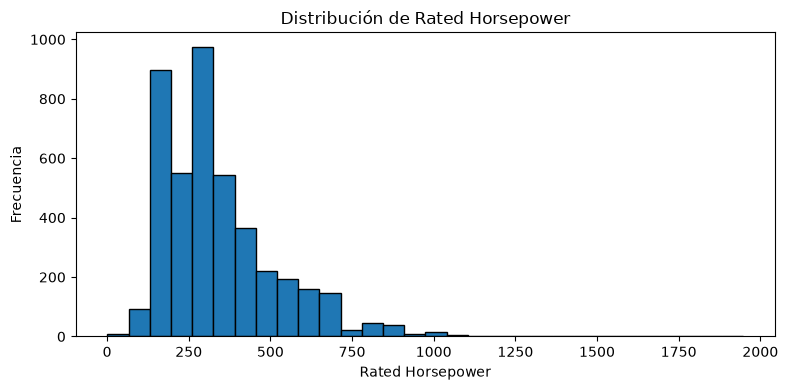

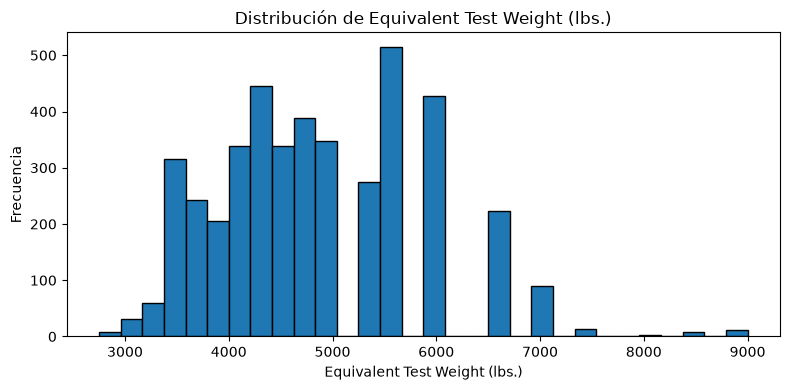

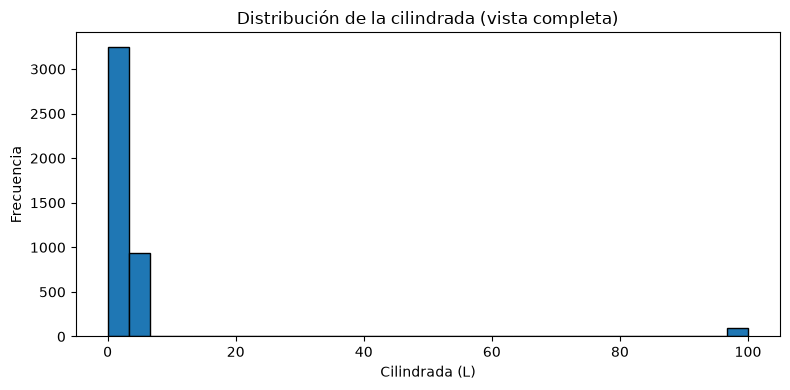

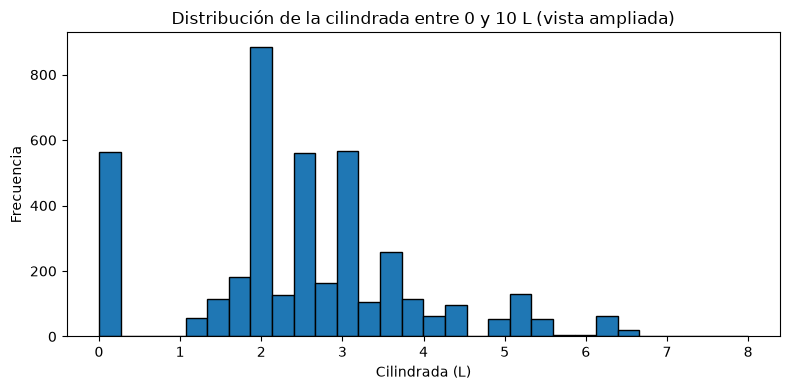

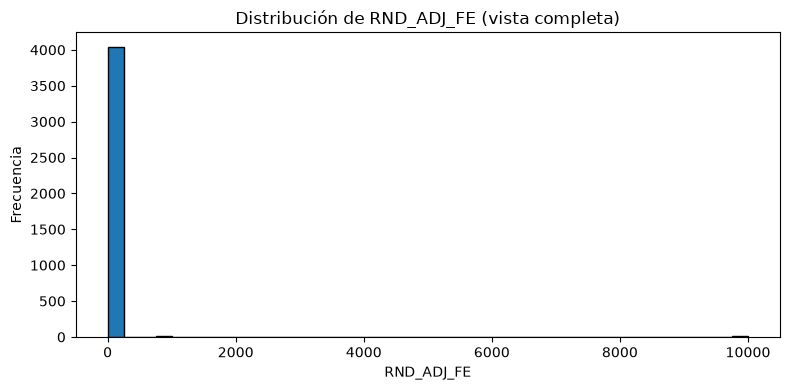

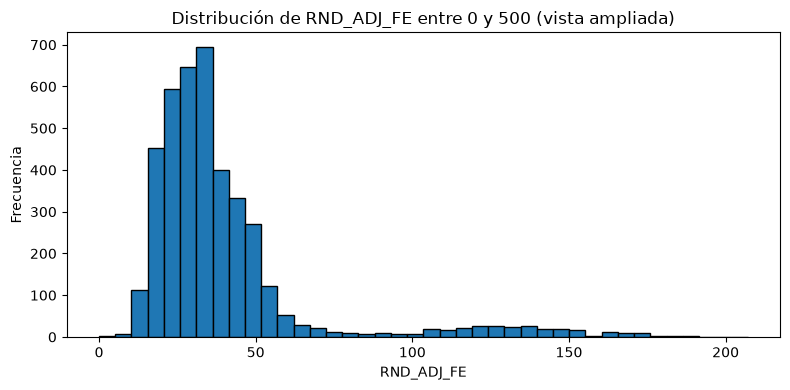

In [14]:
# Distribución de potencia y peso de prueba.
for variable in ["Rated Horsepower", "Equivalent Test Weight (lbs.)"]:
    plt.figure(figsize=(8, 4))
    plt.hist(df[variable].dropna(), bins=30, edgecolor="black")
    plt.title(f"Distribución de {variable}")
    plt.xlabel(variable)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

# Cilindrada: vista completa.
plt.figure(figsize=(8, 4))
plt.hist(df["Test Veh Displacement (L)"].dropna(), bins=30, edgecolor="black")
plt.title("Distribución de la cilindrada (vista completa)")
plt.xlabel("Cilindrada (L)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# Cilindrada: vista ampliada para observar la zona habitual.
# Este filtro solo se usa para el gráfico, no para eliminar datos de df.
cilindrada_ampliada = df.loc[
    df["Test Veh Displacement (L)"].between(0, 10),
    "Test Veh Displacement (L)"
].dropna()

plt.figure(figsize=(8, 4))
plt.hist(cilindrada_ampliada, bins=30, edgecolor="black")
plt.title("Distribución de la cilindrada entre 0 y 10 L (vista ampliada)")
plt.xlabel("Cilindrada (L)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# Economía de combustible: vista completa.
plt.figure(figsize=(8, 4))
plt.hist(df["RND_ADJ_FE"].dropna(), bins=40, edgecolor="black")
plt.title("Distribución de RND_ADJ_FE (vista completa)")
plt.xlabel("RND_ADJ_FE")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# Economía de combustible: vista ampliada para ver mejor la parte central.
# No es una limpieza ni una decisión de eliminar valores.
fe_ampliada = df.loc[df["RND_ADJ_FE"].between(0, 500), "RND_ADJ_FE"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(fe_ampliada, bins=40, edgecolor="black")
plt.title("Distribución de RND_ADJ_FE entre 0 y 500 (vista ampliada)")
plt.xlabel("RND_ADJ_FE")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()


# 2 - Limpieza de base de datos y acciones corretivas

A partir de la exploración inicial del dataset crudo, se detectaron diversas inconsistencias, datos faltantes no estandarizados y registros duplicados. A continuación, se detallan y ejecutan las operaciones de limpieza requeridas, justificando el motivo técnico de cada acción implementada.

## 2.1 Limpieza de filas repetidas
Se genera una copia del conjunto de datos original para proteger la base cruda. Luego, se identifican y eliminan las filas exactamente duplicadas y se revisa la presencia de registros con el mismo identificador de ensayo.


In [15]:
# Creamos una copia para aislar la limpieza del dataframe original
dataset = df.copy()

# Verificamos y eliminamos duplicados exactos en toda la fila
duplicados_exactos = dataset.duplicated().sum()
dataset = dataset.drop_duplicates()

# Revisamos los identificadores de ensayo (Test Number) repetidos
mascara_repetidos = dataset['Test Number'].duplicated(keep=False)
total_registros_repetidos = mascara_repetidos.sum()
ids_unicos_repetidos = dataset.loc[mascara_repetidos, 'Test Number'].nunique()

print(f"Filas duplicadas exactas encontradas y eliminadas: {duplicados_exactos}")
print(f"Registros con 'Test Number' repetido: {total_registros_repetidos}")
print(f"Cantidad de identificadores 'Test Number' únicos que se repiten: {ids_unicos_repetidos}")

Filas duplicadas exactas encontradas y eliminadas: 0
Registros con 'Test Number' repetido: 486
Cantidad de identificadores 'Test Number' únicos que se repiten: 213


## 2.2 Union de columnas
Se procede a unir a Veh Mfr Code + Test Vehicle ID + Test Veh Configuration formando asi un unico identifcador llamado Vehicle_Full_Name

In [16]:
# Identificador único de configuración del vehículo
columnas_id = ['Veh Mfr Code', 'Test Vehicle ID', 'Test Veh Configuration #']

dataset['Vehicle_Config_ID'] = dataset[columnas_id].astype(str).agg('-'.join, axis=1)

# Nombre completo del vehículo
dataset['Vehicle_Full_Name'] = (dataset['Represented Test Veh Make'].astype(str).str.strip() + " " + dataset['Represented Test Veh Model'].astype(str).str.strip())

# Verificamos los nuevos atributos
print(f"Configuraciones únicas: {dataset['Vehicle_Config_ID'].nunique()}")

# Jupyter renderiza automáticamente al dejar el DataFrame al final de la celda
dataset[['Vehicle_Config_ID', 'Vehicle_Full_Name']].head()



Configuraciones únicas: 1448


,Vehicle_Config_ID,Vehicle_Full_Name
0,ASX-5723PT5601-0,Aston Martin DB12 V8
1,ASX-5723PT5601-0,Aston Martin DB12 V8
2,ASX-8841PT8473-0,Aston Martin DBX 707
3,ASX-8841PT8473-0,Aston Martin DBX 707
4,ASX-370TT7334-0,Aston Martin Vanquish


## 2.3 Tratamiento de nulos
Se descartan las variables con más del 95% de datos faltantes, ya que no aportan información representativa para el análisis estadístico (según el diccionario, corresponden principalmente a ensayos analíticos o combinados).


In [17]:
# Calculamos el porcentaje de valores nulos de cada columna
porcentaje_nulos = dataset.isna().mean() * 100

# Identificamos las columnas que superan el 95% de nulos
columnas_nulos_altos = porcentaje_nulos[porcentaje_nulos > 95].index.tolist()

print("Columnas eliminadas por superar el 95 % de nulos:")
print(columnas_nulos_altos)

# Eliminamos las columnas del dataset reasignando la variable
dataset = dataset.drop(columns=columnas_nulos_altos)

Columnas eliminadas por superar el 95 % de nulos:
['ADFE Test Number', 'ADFE Total Road Load HP', 'ADFE Equiv. Test Weight (lbs.)', 'ADFE N/V Ratio', 'Averaging Group ID', 'Averaging Weighting Factor']


## 2.4 Eliminación de columnas constantes
Se eliminan aquellas columnas que poseen un único valor en todos los registros (como el año del modelo o la unidad de medida), ya que al carecer de varianza resultan redundantes para la validación de hipótesis.

In [18]:
# Calculamos la cantidad de valores únicos de todas las columnas a la vez
conteo_unicos = dataset.nunique(dropna=False)

# Filtramos los nombres de las columnas que tienen exactamente 1 valor
columnas_constantes = conteo_unicos[conteo_unicos == 1].index.tolist()

print(f"Columnas constantes eliminadas:\n{columnas_constantes}")

# Eliminamos las columnas constantes del dataset
dataset = dataset.drop(columns=columnas_constantes)

Columnas constantes eliminadas:
['Model Year', 'FE_UNIT']


## 2.5 Detección de valores atípicos mediante el método IQR
Se cuantifica la presencia de posibles outliers en las variables cuantitativas clave calculando los límites inferior y superior. Esto permite identificar valores atípicos extremos y determinar si requieren algún tratamiento especial previo a las pruebas de hipótesis.

In [19]:
# Variables cuantitativas a analizar
variables_outliers = [
    'Test Veh Displacement (L)',
    'Rated Horsepower',
    '# of Cylinders and Rotors',
    '# of Gears',
    'Equivalent Test Weight (lbs.)',
    'Axle Ratio',
    'N/V Ratio',
    'RND_ADJ_FE'
]

# Convertimos las columnas a numéricas para evitar errores de tipo
df_num = dataset[variables_outliers].apply(pd.to_numeric, errors='coerce')

# Calculamos cuartiles e IQR para todas las columnas en una sola operación vectorizada
q1 = df_num.quantile(0.25)
q3 = df_num.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Contamos los outliers por columna
cantidad_outliers = ((df_num < limite_inferior) | (df_num > limite_superior)).sum()

# Construimos la tabla de resumen
resumen_outliers = pd.DataFrame({'Límite inferior': limite_inferior.round(2),'Límite superior': limite_superior.round(2),'Posibles outliers': cantidad_outliers})

# Jupyter renderiza automáticamente el DataFrame al dejarlo al final de la celda
resumen_outliers

,Límite inferior,Límite superior,Posibles outliers
Test Veh Displacement (L),0.48,4.51,995
Rated Horsepower,-111.00,721.00,141
# of Cylinders and Rotors,1.00,9.00,28
# of Gears,-9.50,18.50,0
Equivalent Test Weight (lbs.),1750.00,7750.00,23
Axle Ratio,2.15,4.95,861
N/V Ratio,13.10,40.30,732
RND_ADJ_FE,-4.80,72.80,328


### Filtrado de registros según RND_ADJ_FE

Como criterio adicional de limpieza, se decidió trabajar únicamente con los registros cuyo valor de `RND_ADJ_FE` es menor o igual a 500. De esta manera, se excluyen las observaciones que superan ese umbral, consideradas fuera del rango adoptado para los análisis posteriores.

Es importante aclarar que esta operación filtra filas completas, no columnas. Además, los registros que tienen un valor nulo en `RND_ADJ_FE` también quedan excluidos, ya que no cumplen la condición establecida en el filtro.

In [20]:
##nos quedamos solo con las variables que son menores a 500
dataset = dataset[dataset['RND_ADJ_FE'] <= 500]

## 2.6 Resumen del estado final de la base de datos
Se evalúan las dimensiones finales del conjunto de datos tras las etapas de limpieza, reducción de dimensionalidad y eliminación de columnas redundantes, verificando la presencia de los valores nulos restantes.

In [21]:
print("Dimensiones de la base original:", df.shape)
print("Dimensiones de la base limpia:", dataset.shape)

## Verificación de nulos restantes
print("\nCantidad de valores nulos restantes:")
print(dataset.isna().sum().sort_values(ascending=False).head(15))

print("\nPrimeros registros de la base limpia:")
dataset.head()

Dimensiones de la base original: (4287, 67)
Dimensiones de la base limpia: (4042, 61)

Cantidad de valores nulos restantes:
PM (g/mi)                     3656
FE Bag 4                      3654
FE Bag 3                      2598
FE Bag 2                      2187
FE Bag 1                      2187
N2O (g/mi)                    1887
CH4 (g/mi)                     950
NOx (g/mi)                     739
CO (g/mi)                      724
THC (g/mi)                     723
Aftertreatment Device Cd       565
Aftertreatment Device Desc     565
# of Cylinders and Rotors      565
CO2 (g/mi)                     559
DT-Energy Economy Rating       551
dtype: int64

Primeros registros de la base limpia:


,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,...,Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Method Cd,Averging Method Desc,Vehicle_Config_ID,Vehicle_Full_Name
0,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,N,No averaging,ASX-5723PT5601-0,Aston Martin DB12 V8
1,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,...,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,N,No averaging,ASX-5723PT5601-0,Aston Martin DB12 V8
2,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,N,No averaging,ASX-8841PT8473-0,Aston Martin DBX 707
3,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,...,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,N,No averaging,ASX-8841PT8473-0,Aston Martin DBX 707
4,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,825,...,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,N,No averaging,ASX-370TT7334-0,Aston Martin Vanquish


# 3. Planteo de hipótesis

En esta etapa se presentan tres hipótesis propias del trabajo. Se aborda una hipótesis univariada, una bivariada y una multivariada. Para cada una se identifican las variables involucradas y se explica su motivación a partir de las características del dominio estudiado.

## 3.1. Hipótesis univariada

**Hipótesis:** Al analizar conjuntamente vehículos con motores de combustión interna y vehículos eléctricos, la distribución de la economía de combustible ajustada (`RND_ADJ_FE`) presentará una asimetría positiva y dos concentraciones diferenciadas de valores, asociadas a las distintas tecnologías de propulsión.

**Variable involucrada:** `RND_ADJ_FE` — cuantitativa continua.

**Motivación:** Los vehículos con diferentes sistemas de propulsión pueden presentar comportamientos muy distintos en términos de economía de combustible. Al reunirlos en una misma distribución, es posible que aparezcan concentraciones diferenciadas y que los valores elevados generen una cola hacia la derecha. Analizar la forma de la distribución permite determinar si una medida general, como la media, representa adecuadamente al conjunto de vehículos.

## 3.2. Hipótesis bivariada

**Hipótesis:** A medida que aumenta el peso equivalente de prueba del vehículo (`Equivalent Test Weight`), disminuye su economía de combustible ajustada (`RND_ADJ_FE`) en el grupo de vehículos analizado como de combustión.

**Variables involucradas:**
- `Equivalent Test Weight (lbs.)` — cuantitativa continua.
- `RND_ADJ_FE` — cuantitativa continua.

**Motivación:** Desde el punto de vista físico y de la ingeniería automotriz, un vehículo de mayor peso necesita más energía para ponerse en movimiento y mantenerlo, debido a factores como la inercia y la resistencia al rodamiento. Por este motivo, se espera que un mayor peso esté asociado con una menor cantidad de millas recorridas por galón de combustible.

## 3.3. Hipótesis multivariada

**Hipótesis:** El efecto de la potencia nominal del vehículo (`Rated Horsepower`) sobre la economía de combustible ajustada (`RND_ADJ_FE`) varía según el tipo de energía utilizado. Se espera que el deterioro de la economía de combustible asociado a una mayor potencia sea menos marcado en los vehículos eléctricos que en los vehículos de combustión.

**Variables involucradas:**
- `Rated Horsepower` — cuantitativa.
- `RND_ADJ_FE` — cuantitativa continua.
- `Test Fuel Type Description` — cualitativa nominal.

**Motivación:** En los vehículos de combustión interna, un aumento de potencia suele estar asociado con un mayor consumo de combustible. En cambio, los motores eléctricos presentan características de eficiencia diferentes, por lo que se plantea que la relación entre potencia y economía de combustible podría variar según la fuente de energía del vehículo.

# 4. Validación de hipótesis

## 4.1. Validación de la hipótesis univariada

Se comienza examinando la distribución de `RND_ADJ_FE` mediante un gráfico Q-Q (*Quantile-Quantile Plot*), que permite comparar los cuantiles observados con los que se esperarían bajo una distribución normal.

Como complemento, se plantea un contraste de normalidad:

- **Hipótesis nula (H₀):** la variable `RND_ADJ_FE` sigue una distribución normal.
- **Hipótesis alternativa (H₁):** la variable `RND_ADJ_FE` no sigue una distribución normal.

Se establece un nivel de significancia de **α = 0,05**.

Este contraste permite evaluar la normalidad de la distribución, aunque no determina por sí mismo si existe bimodalidad. Para examinar las concentraciones de valores también se utilizará un histograma.

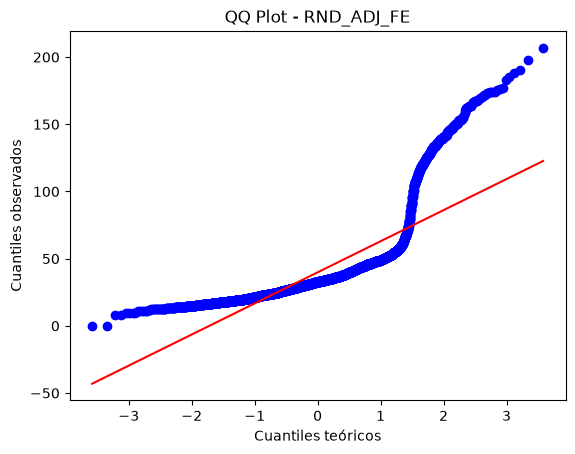

In [22]:

stats.probplot(dataset["RND_ADJ_FE"].dropna(), dist="norm", plot=plt)

plt.title("QQ Plot - RND_ADJ_FE")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")

plt.show()

En el gráfico Q-Q se observa que los puntos se apartan de la línea de referencia, especialmente en los extremos. Esta desviación constituye un indicio gráfico de que la distribución de `RND_ADJ_FE` no se ajusta a una distribución normal.

A continuación, se complementa la observación visual mediante las pruebas estadísticas de Shapiro-Wilk y Kolmogorov-Smirnov.

In [23]:

#test de shapiro
stat, p = shapiro(dataset["RND_ADJ_FE"].dropna())
print(f"Test de Shapiro-Wilk para variable RND_ADJ_FE: Estadístico={stat:.3f}, p-valor={p:.3f}")

#test de kolmogorov-smirnov en este caso es el mas adecuado por su el gran tamaño de datos
stat, p = kstest(dataset["RND_ADJ_FE"].dropna(), 'norm')
print(f"Test de Kolmogorov-Smirnov para variable RND_ADJ_FE: Estadístico={stat:.3f}, p-valor={p:.3f}")


Test de Shapiro-Wilk para variable RND_ADJ_FE: Estadístico=0.663, p-valor=0.000
Test de Kolmogorov-Smirnov para variable RND_ADJ_FE: Estadístico=1.000, p-valor=0.000


se verifica que no cumple el supuesto de normalidad, seguimor analisando con un histograma con una curva de densidad y se calculan las estadísticas descriptivas de `RND_ADJ_FE`. Esto permite observar la concentración de los valores, la posible presencia de más de un grupo y la relación entre la media y la mediana.

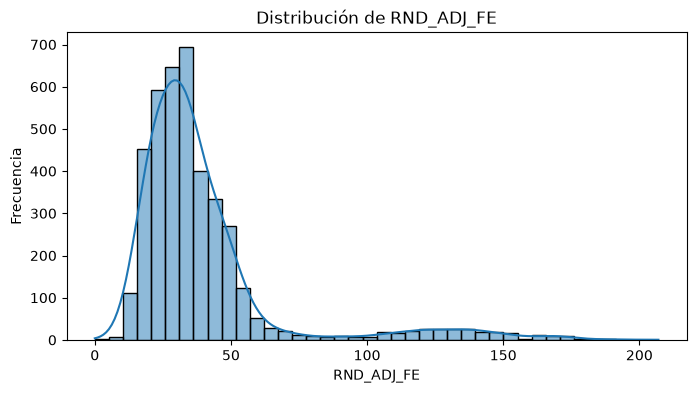

count    4042.000000
mean       39.820980
std        28.407734
min         0.000000
25%        24.300000
50%        32.800000
75%        43.400000
max       207.000000
Name: RND_ADJ_FE, dtype: float64

In [24]:

plt.figure(figsize=(8, 4))
sns.histplot(
    dataset["RND_ADJ_FE"].dropna(),
    bins=40,
    kde=True,
    edgecolor="black"
)

plt.title("Distribución de RND_ADJ_FE")
plt.xlabel("RND_ADJ_FE")
plt.ylabel("Frecuencia")

plt.show()

#describe() para ver sus estadisticos
dataset["RND_ADJ_FE"].describe()

sepuede observar el grafico sesgado a la derecha, aparte de su estadistico donde la media>mediana denontado lo mismo dicho anterioremnte, ahora hacemos el estadisticos de coeficiente de asimetrimetria de fisher-pearson

In [25]:
skewness = stats.skew(dataset['RND_ADJ_FE'])
print(f"coeficiente de asimetria (fisher-pearson): {skewness:.2f}")

coeficiente de asimetria (fisher-pearson): 2.77


mayor a cero por lo taro preseta asimetria positiva
ahora veremos los graficos(historigramas) del combustion y electrico por separado con su kde

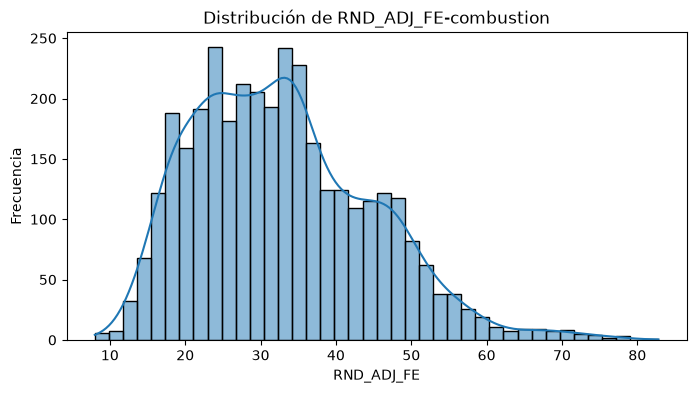

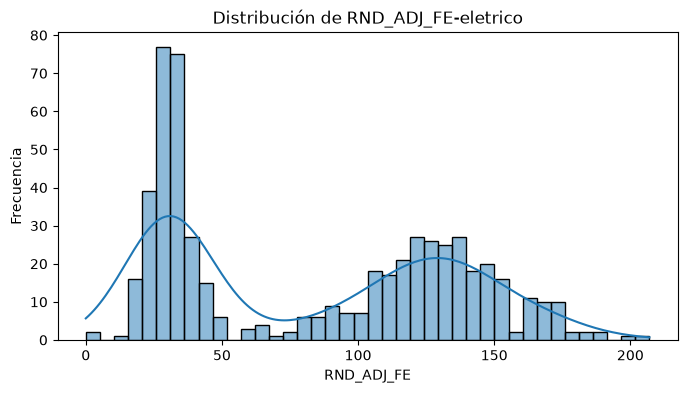

In [26]:
#nos quedamos con los de combustion 
combustibles_excluir = ['Electricity', 'Hydrogen 5']
combustion = dataset[~dataset['Test Fuel Type Description'].isin(combustibles_excluir)]

#eletrico
electrico = dataset[dataset['Test Fuel Type Description'].isin(combustibles_excluir)]

#combustion
plt.figure(figsize=(8, 4))
sns.histplot(
    combustion["RND_ADJ_FE"].dropna(),
    bins=40,
    kde=True,
    edgecolor="black"
)

plt.title("Distribución de RND_ADJ_FE-combustion")
plt.xlabel("RND_ADJ_FE")
plt.ylabel("Frecuencia")

plt.show()

#eletrico
plt.figure(figsize=(8, 4))
sns.histplot(
    electrico["RND_ADJ_FE"].dropna(),
    bins=40,
    kde=True,
    edgecolor="black"
)

plt.title("Distribución de RND_ADJ_FE-eletrico")
plt.xlabel("RND_ADJ_FE")
plt.ylabel("Frecuencia")

plt.show()



Se puede observarel en el segundo grafico el segundo pico (entre 100 y 160 MPGe) corresponde a la masa de vehículos 100% eléctricos,en cuya eficiencia energética equivalente (MPGe) es significativamente mayor.En cuanto al grafico de combustion se puede observar un solo pico(unimodal), por lo tanto al unirce y trabajar los dos tipos de auto(electrico y combustion) en un mismo dataset su grafica presentara bimodalidad y no tendra el supuesto de normalidad y estara sesgado a la derecha como se demostro estadisticamente con los test anteriormente utilizado y el describe()


**Resultado: la hipótesis queda respaldada en cuanto a la asimetría positiva y a la presencia visual de dos concentraciones de valores. No obstante, las pruebas de normalidad realizadas permiten concluir que la distribución no es normal y esta sesgada a la derecha, pero no constituyen por sí mismas una prueba formal de bimodalidad.**

## 4.2. Validación de la hipótesis bivariada

Se plantea el siguiente contraste para evaluar la relación entre el peso equivalente de prueba y la economía de combustible:

- **Hipótesis nula (H₀):** no existe una asociación negativa entre el peso del vehículo y su economía de combustible (ρ ≥ 0).
- **Hipótesis alternativa (H₁):** existe una asociación negativa entre ambas variables; a mayor peso, menor economía de combustible (ρ < 0).

Se establece un nivel de significancia de **α = 0,05**.

Para realizar el análisis, se excluyen los registros cuyo tipo de combustible es `Electricity` o `Hydrogen 5`. Luego, se conservan los registros que cuentan con valores informados tanto para `RND_ADJ_FE` como para `Equivalent Test Weight (lbs.)`.

In [27]:
# 2. Excluir vehículos que no son de combustión interna
combustibles_excluir = ['Electricity', 'Hydrogen 5']
df_combustion = dataset[~dataset['Test Fuel Type Description'].isin(combustibles_excluir)]

# 3. Limpiar valores nulos en la variable dependiente e independiente
df_analisis = df_combustion.dropna(subset=['RND_ADJ_FE', 'Equivalent Test Weight (lbs.)']) 


### Evaluación del supuesto de normalidad

Antes de seleccionar el estadístico de asociación, se examina la normalidad de ambas variables mediante gráficos Q-Q. Se analiza por separado la distribución del peso equivalente de prueba y la de la economía de combustible ajustada.

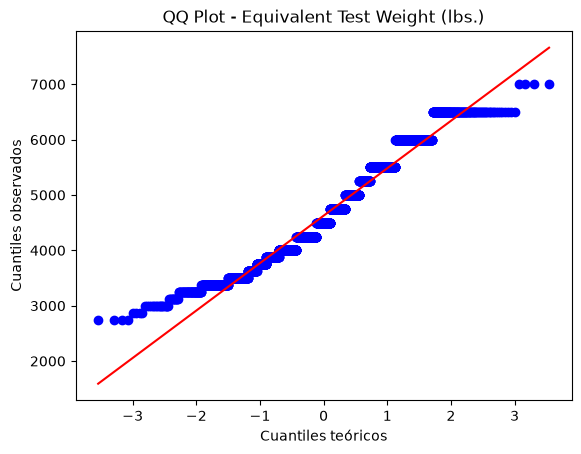

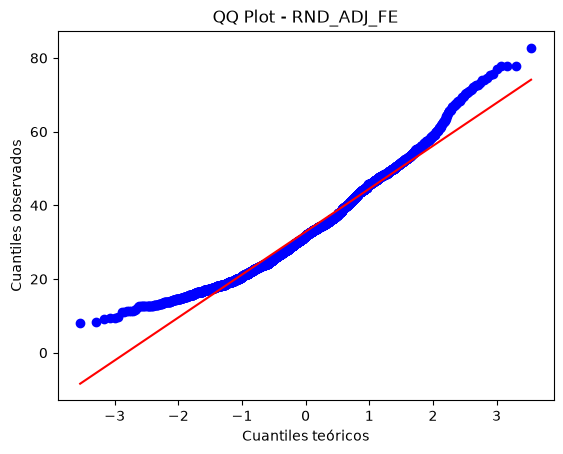

In [28]:
stats.probplot(df_analisis["Equivalent Test Weight (lbs.)"].dropna(), dist="norm", plot=plt)

plt.title("QQ Plot - Equivalent Test Weight (lbs.)")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")

plt.show()

stats.probplot(df_analisis["RND_ADJ_FE"].dropna(), dist="norm", plot=plt)

plt.title("QQ Plot - RND_ADJ_FE")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")

plt.show()

En ambos gráficos Q-Q se observa que los puntos se apartan de la línea de referencia. Esto indica que las variables no presentan un ajuste visual adecuado a la distribución normal.

Para complementar esta observación, se realizan las pruebas estadísticas de Shapiro-Wilk y Kolmogorov-Smirnov.

In [29]:

#test de shapiro
stat, p = shapiro(df_analisis["RND_ADJ_FE"].dropna())
print(f"Test de Shapiro-Wilk para variable RND_ADJ_FE: Estadístico={stat:.3f}, p-valor={p:.3f}")


#test de shapiro
stat, p = shapiro(df_analisis["Equivalent Test Weight (lbs.)"].dropna())
print(f"Test de Shapiro-Wilk para variable Equivalent Test Weight (lbs.): Estadístico={stat:.3f}, p-valor={p:.3f}")

print()
print("ahora con kolmogorov")
print()

#test de kolmogorov-smirnov para RND_ADJ_FE
stat, p = kstest(df_analisis["RND_ADJ_FE"].dropna(), 'norm')
print(f"Test de Kolmogorov-Smirnov para variable RND_ADJ_FE: Estadístico={stat:.3f}, p-valor={p:.3f}")

#test de kolmogorov-smirnov para Equivalent Test Weight (lbs.)
stat, p = kstest(df_analisis["Equivalent Test Weight (lbs.)"].dropna(), 'norm')
print(f"Test de Kolmogorov-Smirnov para variable Equivalent Test Weight (lbs.): Estadístico={stat:.3f}, p-valor={p:.3f}")



Test de Shapiro-Wilk para variable RND_ADJ_FE: Estadístico=0.970, p-valor=0.000
Test de Shapiro-Wilk para variable Equivalent Test Weight (lbs.): Estadístico=0.962, p-valor=0.000

ahora con kolmogorov

Test de Kolmogorov-Smirnov para variable RND_ADJ_FE: Estadístico=1.000, p-valor=0.000
Test de Kolmogorov-Smirnov para variable Equivalent Test Weight (lbs.): Estadístico=1.000, p-valor=0.000


Los resultados de Shapiro-Wilk arrojan p-valores inferiores a 0,001 para `RND_ADJ_FE` y para `Equivalent Test Weight (lbs.)`. Por lo tanto, con α = 0,05, se rechaza el supuesto de normalidad para ambas variables.

Las pruebas de Kolmogorov-Smirnov también muestran p-valores inferiores a 0,001 en la ejecución realizada. Al igual que en el análisis anterior, estos resultados deben interpretarse con cautela porque el código compara los datos sin estandarizar con una distribución normal estándar.

A continuación, se revisa la comparación de varianzas mediante la prueba de Levene.

In [30]:
stat, p = stats.levene(df_analisis["RND_ADJ_FE"], df_analisis["Equivalent Test Weight (lbs.)"])
print(f"Test de Levene para Equivalent Test Weight (lbs.) y RND_ADJ_FE: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para Equivalent Test Weight (lbs.) y RND_ADJ_FE: Estadístico=6873.245, p-valor=0.000


La prueba de Levene arroja un p-valor inferior a 0,001. El código aplica esta prueba directamente sobre las dos variables cuantitativas. Sin embargo, al tratarse de magnitudes diferentes, este resultado no debe interpretarse como una evaluación formal de la homocedasticidad de la relación entre ellas.

Dado que las variables no presentan normalidad, se utiliza el coeficiente de correlación de Spearman para evaluar la dirección y la intensidad de su asociación monotónica. Este estadístico no requiere el supuesto de normalidad.

In [31]:
stat, p_value = stats.spearmanr(df_analisis["RND_ADJ_FE"], df_analisis["Equivalent Test Weight (lbs.)"])
print(f"Coeficiente de Spearman (rho): {stat:.4f} y P-valor: {p_value:.4f}")


Coeficiente de Spearman (rho): -0.5154 y P-valor: 0.0000


Finalmente, se construye un gráfico de dispersión entre `Equivalent Test Weight (lbs.)` y `RND_ADJ_FE`. Este recurso permite observar visualmente el comportamiento conjunto de ambas variables y complementar la interpretación del coeficiente de Spearman.

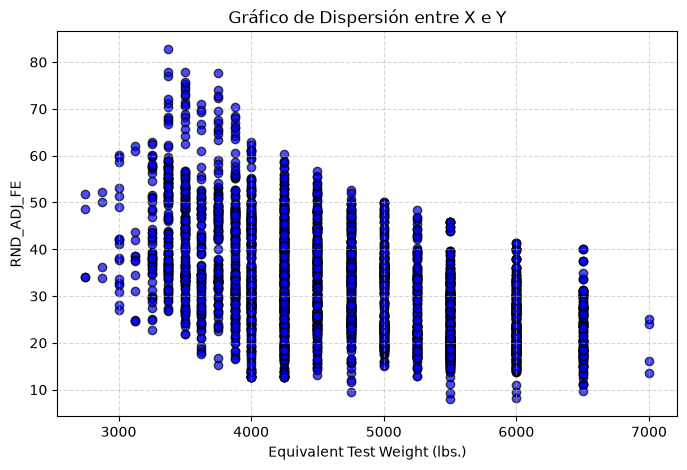

In [32]:
plt.figure(figsize=(8, 5))
plt.scatter(df_analisis["Equivalent Test Weight (lbs.)"], df_analisis["RND_ADJ_FE"], color='blue', alpha=0.7, edgecolors='black')

# Personalización
plt.title('Gráfico de Dispersión entre X e Y')
plt.xlabel('Equivalent Test Weight (lbs.)')
plt.ylabel('RND_ADJ_FE')
plt.grid(True, linestyle='--', alpha=0.5)

# Mostrar el gráfico
plt.show()

El coeficiente de Spearman obtenido es **ρ = -0,5154**, con un p-valor inferior a **0,001**. Dado que el p-valor es menor que el nivel de significancia establecido (0,05), se rechaza la hipótesis nula.

El coeficiente negativo indica una asociación monotónica inversa de intensidad moderada: en general, los vehículos de mayor peso equivalente de prueba tienden a presentar valores menores de economía de combustible. El gráfico de dispersión acompaña esta tendencia, especialmente en los registros comprendidos aproximadamente entre 4.000 y 7.000 libras.

**Resultado: la hipótesis queda respaldada. Se encuentra evidencia estadísticamente significativa de una asociación negativa entre el peso equivalente de prueba y la economía de combustible ajustada en el grupo analizado.**

## 4.3. Validación de la hipótesis multivariada

Se analiza si la relación entre la potencia nominal (`Rated Horsepower`) y la economía de combustible ajustada (`RND_ADJ_FE`) presenta diferencias según el tipo de energía utilizado por el vehículo.

### Separación de los grupos de análisis

En primer lugar, se divide el conjunto de datos en dos grupos según el tipo de combustible o fuente de energía. De acuerdo con el criterio implementado en el código, los registros con `Electricity` y `Hydrogen 5` se agrupan en `df_electrico`, mientras que los restantes se incorporan a `df_combustion`.

Por lo tanto, el grupo denominado `df_electrico` incluye tanto vehículos eléctricos como registros de hidrógeno.

In [33]:
#Excluir vehículos que no son de combustión interna
combustibles_excluir = ['Electricity', 'Hydrogen 5']
df_combustion = dataset[~dataset['Test Fuel Type Description'].isin(combustibles_excluir)]

#Excluir vehículos que no son electricos
df_electrico = dataset[dataset['Test Fuel Type Description'].isin(combustibles_excluir)]



### Análisis gráfico de la relación entre potencia y economía de combustible

Una vez separados los grupos, se construye un gráfico de dispersión para observar la relación entre `Rated Horsepower` y `RND_ADJ_FE` en los vehículos agrupados como eléctricos y en los agrupados como de combustión.

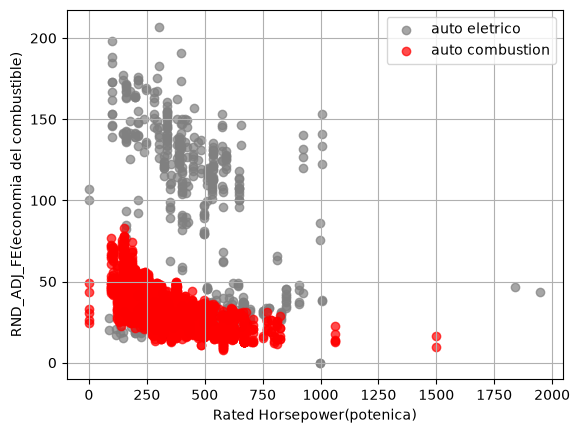

In [34]:


plt.scatter(df_electrico['Rated Horsepower'], df_electrico['RND_ADJ_FE'], color="gray", alpha=0.70, label="auto eletrico")
plt.scatter(df_combustion['Rated Horsepower'], df_combustion['RND_ADJ_FE'], color="red", alpha=0.70, label="auto combustion")

#Agregamos una grilla, los nombres de los ejes
plt.grid(True)
plt.xlabel('Rated Horsepower(potenica)')
plt.ylabel('RND_ADJ_FE(economia del combustible)')
#Agregamos leyenda
plt.legend()
#Mostramos el grafico
plt.show()

En el gráfico se observa que los registros del grupo eléctrico e hidrógeno presentan, en general, valores de `RND_ADJ_FE` superiores a los del grupo de combustión para distintos niveles de potencia. También se aprecia que ambos grupos presentan distribuciones diferentes.

Esta comparación gráfica permite explorar el comportamiento de las variables, pero no es suficiente por sí sola para determinar si la relación entre potencia y economía de combustible difiere significativamente entre los grupos.

A continuación, se examina la normalidad de `RND_ADJ_FE` en cada grupo mediante gráficos Q-Q.

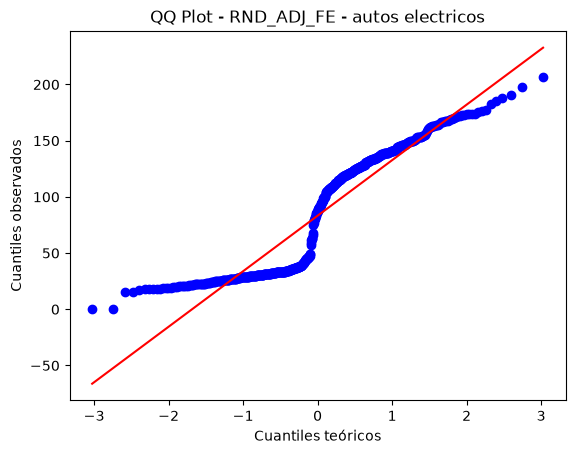

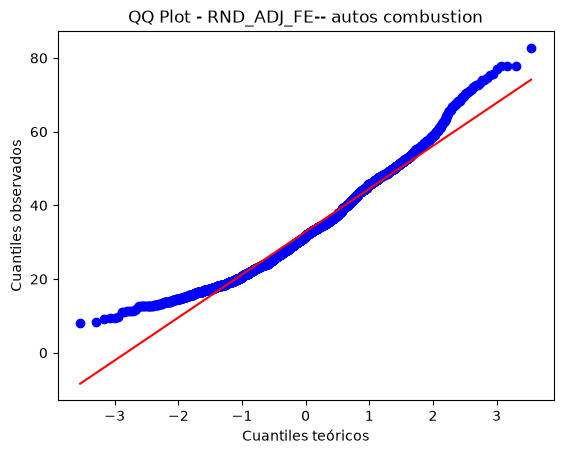

In [35]:
stats.probplot(df_electrico["RND_ADJ_FE"].dropna(), dist="norm", plot=plt)

plt.title("QQ Plot - RND_ADJ_FE - autos electricos")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")

plt.show()

stats.probplot(df_combustion["RND_ADJ_FE"].dropna(), dist="norm", plot=plt)

plt.title("QQ Plot - RND_ADJ_FE-- autos combustion")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")

plt.show()

En los dos gráficos Q-Q se observa que los puntos se apartan de la línea de referencia, lo que indica que la distribución de `RND_ADJ_FE` no presenta un ajuste visual adecuado a la normalidad en ninguno de los grupos.

Esta observación se complementa mediante la prueba estadística de Shapiro-Wilk.

In [36]:
#test de shapiro
stat, p = shapiro(df_electrico["RND_ADJ_FE"].dropna())
print(f"Test de Shapiro-Wilk para variable RND_ADJ_FE-electrico: Estadístico={stat:.3f}, p-valor={p:.3f}")

#test de shapiro
stat, p = shapiro(df_combustion["RND_ADJ_FE"].dropna())
print(f"Test de Shapiro-Wilk para variable RND_ADJ_FE-combustion: Estadístico={stat:.3f}, p-valor={p:.3f}")


Test de Shapiro-Wilk para variable RND_ADJ_FE-electrico: Estadístico=0.870, p-valor=0.000
Test de Shapiro-Wilk para variable RND_ADJ_FE-combustion: Estadístico=0.970, p-valor=0.000


La prueba de Shapiro-Wilk arroja p-valores inferiores a 0,001 tanto para el grupo eléctrico e hidrógeno como para el grupo de combustión. Por lo tanto, se rechaza el supuesto de normalidad en ambos grupos.

A continuación, se aplica la prueba de Levene para comparar la igualdad de varianzas de `RND_ADJ_FE` entre los dos grupos.

In [37]:
stat, p = stats.levene(df_combustion["RND_ADJ_FE"], df_electrico["RND_ADJ_FE"])
print(f"Test de Levene para RND_ADJ_FE: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para RND_ADJ_FE: Estadístico=7935.005, p-valor=0.000


La prueba de Levene arroja un p-valor inferior a 0,001, por lo que se rechaza la hipótesis de igualdad de varianzas entre los grupos.

Luego, el código calcula correlaciones de Spearman para cada grupo. Es importante señalar que las variables utilizadas en esas correlaciones son `Rated Horsepower` y `Equivalent Test Weight (lbs.)`, y no `Rated Horsepower` y `RND_ADJ_FE`. Por lo tanto, esos coeficientes describen la asociación entre potencia y peso, pero no permiten verificar directamente la relación entre potencia y economía de combustible planteada en la hipótesis.

In [38]:
print("--- Correlación de Spearman (Potencia vs Economía) --- para autos electrico")
stat, p_value = stats.spearmanr(df_electrico["Rated Horsepower"], df_electrico["Equivalent Test Weight (lbs.)"])
print(f"Coeficiente de Spearman (rho) : {stat:.4f} y P-valor: {p_value:.4f}")

#interpretacion del resultado
alpha = 0.05  # Nivel de significancia

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una correlación significativa entre la Potencia y la Economía de Combustible.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una correlación significativa entre la Potencia y la Economía de Combustible.")

print()
print("--- Correlación de Spearman (Potencia vs Economía) --- para autos a combustion")
stat, p_value = stats.spearmanr(df_combustion["Rated Horsepower"], df_combustion["Equivalent Test Weight (lbs.)"])
print(f"Coeficiente de Spearman (rho): {stat:.4f} y P-valor: {p_value:.4f}")

#interpretacion del resultado
alpha = 0.05  # Nivel de significancia

if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una correlación significativa entre la Potencia y la Economía de Combustible.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una correlación significativa entre la Potencia y la Economía de Combustible.")

--- Correlación de Spearman (Potencia vs Economía) --- para autos electrico
Coeficiente de Spearman (rho) : 0.6658 y P-valor: 0.0000
Se rechaza la hipótesis nula.
Existe una correlación significativa entre la Potencia y la Economía de Combustible.

--- Correlación de Spearman (Potencia vs Economía) --- para autos a combustion
Coeficiente de Spearman (rho): 0.5887 y P-valor: 0.0000
Se rechaza la hipótesis nula.
Existe una correlación significativa entre la Potencia y la Economía de Combustible.


Los coeficientes de Spearman obtenidos son **ρ = 0,6658** para el grupo eléctrico e hidrógeno y **ρ = 0,5887** para el grupo de combustión, con p-valores inferiores a 0,001 en ambos casos. Estos resultados indican una asociación monotónica positiva entre potencia y peso equivalente de prueba dentro de cada grupo.

Posteriormente, se calcula para cada registro la variable `Severidad_Ratio`, definida como el cociente entre `RND_ADJ_FE` y `Rated Horsepower`. Luego, se utiliza la prueba U de Mann-Whitney para comparar este indicador entre los dos grupos.

El resultado de Mann-Whitney es **U = 1.212.822**, con un p-valor inferior a **0,001**, lo que indica una diferencia estadísticamente significativa entre las distribuciones del indicador `Severidad_Ratio`.

In [39]:
df_electrico['Severidad_Ratio'] = df_electrico['RND_ADJ_FE'] /  df_electrico['Rated Horsepower']
df_combustion['Severidad_Ratio'] = df_combustion['RND_ADJ_FE'] / df_combustion['Rated Horsepower']

# Test de Mann-Whitney U para comparar Population_mln entre países desarrollados y en vías de desarrollo
stat, p = stats.mannwhitneyu(df_electrico['Severidad_Ratio'], df_combustion['Severidad_Ratio'])
print(f"Test de Mann-Whitney U para Population_mln: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Interpretación de los resultados
alpha = 0.05  # Nivel de significancia
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa entre vehiculos electricos y vehiculos de combustion.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa entre vehiculos electricos y vehiculos de combustion.")

Test de Mann-Whitney U para Population_mln: Estadístico=1212822.000, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa entre vehiculos electricos y vehiculos de combustion.


La prueba U de Mann-Whitney permite identificar una diferencia estadísticamente significativa en el indicador `Severidad_Ratio` entre los grupos comparados. Sin embargo, este resultado no permite establecer por sí solo cuál de los grupos presenta un valor mayor, ni demuestra directamente cómo cambia la economía de combustible a medida que aumenta la potencia.

Además, las correlaciones de Spearman calculadas en el código relacionan potencia con peso equivalente de prueba, no potencia con economía de combustible.

Resultado: se observa una diferencia estadísticamente significativa entre los grupos en el indicador economía de combustible/potencia. No obstante, con los cálculos implementados no es posible confirmar completamente la hipótesis original sobre el efecto de la potencia en la economía de combustible.**

# 3.4 Hipotesis plateadas por la catedra:
### a) La mayoría de las configuraciones de vehículos a combustión alcanzan al menos 25 MPG de economía de combustible en condiciones de conducción urbana.

* **Hipótesis Nula ($H_0$):** $\mu \ge 25$ 
  *(El promedio de rendimiento es de al menos 25 MPG. Representa la afirmación original y siempre contiene la igualdad).*

* **Hipótesis Alternativa ($H_1$):** $\mu < 25$ 
  *(El promedio de rendimiento es inferior a 25 MPG. Es el opuesto lógico estricto de $H_0$).*

  ahora filtramos datos que no vamos a trabajar

In [40]:
# 2. Excluir vehículos que no son de combustión interna y nos quedamos con conduccion urbana
combustibles_excluir = ['Electricity', 'Hydrogen 5']
combustion = dataset[(~dataset['Test Fuel Type Description'].isin(combustibles_excluir)) & (dataset["Test Category"] == "FTP")]

combustios = combustion.dropna(subset=['RND_ADJ_FE'])  # Eliminamos filas con valores nulos en RND_ADJ_FE

ahora usamos QQPLOT Y HITORIGRAMAS para ver visualmente el supuesto de nomalidad

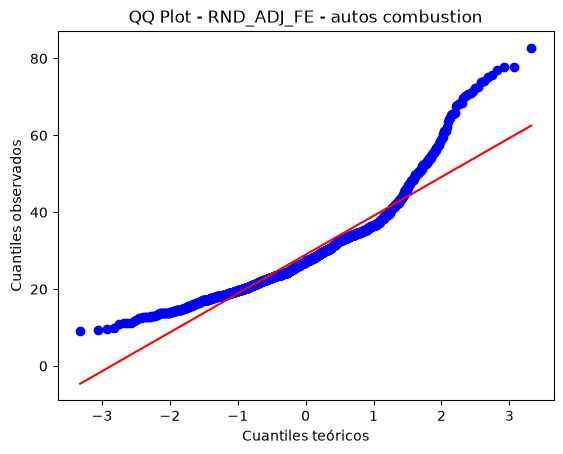

In [41]:
stats.probplot(combustion["RND_ADJ_FE"].dropna(), dist="norm", plot=plt)

plt.title("QQ Plot - RND_ADJ_FE - autos combustion")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.show()

observarmos que los datos no siguen una distribucion normla ,seguimor mirando ahora con un historigrama

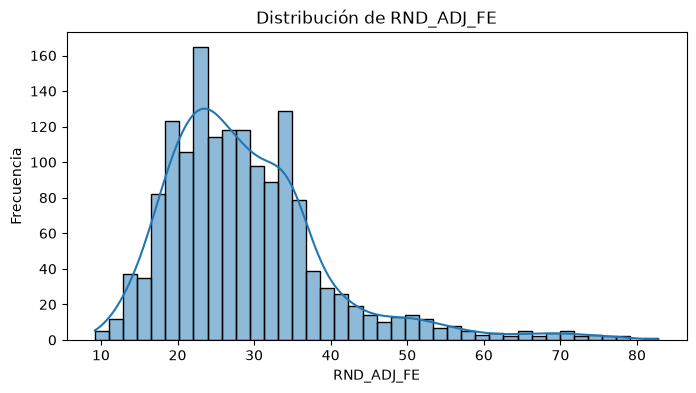

In [42]:

plt.figure(figsize=(8, 4))
sns.histplot(
    combustion["RND_ADJ_FE"].dropna(),
    bins=40,
    kde=True,
    edgecolor="black"
)

plt.title("Distribución de RND_ADJ_FE")
plt.xlabel("RND_ADJ_FE")
plt.ylabel("Frecuencia")

plt.show()


observase puede ver que la distribucion tiene un sesgo no normal,para validar usamos el estadistico de shapiro wilk

In [43]:
#test de shapiro
stat, p = shapiro(combustion["RND_ADJ_FE"].dropna())
print(f"Test de Shapiro-Wilk para variable RND_ADJ_FE-combustion: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk para variable RND_ADJ_FE-combustion: Estadístico=0.896, p-valor=0.000


se puede observar que no se cumple el supuesto de normalidad, utlizamos test no parametricos en este caso la prueba de wilcoxon para una muestra

In [44]:

#  Restar el valor de referencia de la hipótesis (25 MPG)
diferencias = combustion["RND_ADJ_FE"]- 25

#  Ejecutar la Prueba de Wilcoxon unilateral (mediana < 25)
estadistico, p_valor = stats.wilcoxon(diferencias, alternative="less")

#  Mostrar resultados
print(f"Estadístico W: {estadistico}")
print(f"p-valor: {p_valor:.5f}")

#  Interpretación de la prueba
alpha = 0.05

if p_valor < alpha:
    print(
        f"Rechazamos H0 (p-valor = {p_valor:.5f} < {alpha}):"
        "\nExiste evidencia estadística para afirmar que el rendimiento es INFERIOR a 25 MPG."
    )
else:
    print(
        f"No rechazamos H0 (p-valor = {p_valor:.5f} >= {alpha}):"
        "\nNo hay evidencia de que el rendimiento sea inferior a 25 MPG. "
        "Se mantiene que el rendimiento es de al menos 25 MPG."
    )

Estadístico W: 798068.5
p-valor: 1.00000
No rechazamos H0 (p-valor = 1.00000 >= 0.05):
No hay evidencia de que el rendimiento sea inferior a 25 MPG. Se mantiene que el rendimiento es de al menos 25 MPG.


se probo que los datos no son inferior a 25 en mgp ,por lo tanto queda validado la hipotesis que los autos a combustion en coduccion urbana al menos alcanzan un 25mgp en la economia de combustion

# 3.5-  HIPOTESIS B): En vehículos de combustión, la economía de combustible difiere según el sistema de tracción del vehículo

Queremos evaluar si el rendimiento de combustible en ciudad difiere según el tipo de tracción del vehículo (delantera, trasera, integral AWD o 4x4).

**Planteo:**
- $H_0$: Las distribuciones de economía de combustible son iguales entre los sistemas de tracción
- $H_1$: Al menos un sistema de tracción tiene una distribución de economía de combustible diferente
- Nivel de significancia: $\alpha = 0.05$

In [45]:
# Obtenemos la tracción y el MPG promedio por configuración única en combustión urbana
df_traccion = (
    combustion.groupby('Vehicle_Config_ID')
    .agg({'RND_ADJ_FE': 'mean', 'Drive System Description': 'first'})
    .dropna()
)

print("Cantidad de configuraciones por tipo de tracción:")
print(df_traccion['Drive System Description'].value_counts())


Cantidad de configuraciones por tipo de tracción:
Drive System Description
2-Wheel Drive, Front       445
All Wheel Drive            294
2-Wheel Drive, Rear        261
4-Wheel Drive               73
Part-time 4-Wheel Drive     11
Name: count, dtype: int64


primero evaluamos los supuestos: normalidad por grupo con shapiro y homocedasticidad con levene

In [46]:
grupos_traccion = []
nombres_traccion = []

for nombre, subgrupo in df_traccion.groupby('Drive System Description'):
    valores = subgrupo['RND_ADJ_FE'].values
    if len(valores) >= 5:
        grupos_traccion.append(valores)
        nombres_traccion.append(nombre)
        stat, p = stats.shapiro(valores)
        print(f"Tracción: {nombre:25s} | n={len(valores):3d} | Mediana={np.median(valores):.1f} | Shapiro p-valor={p:.4e}")

# Test de Levene
stat_lev, p_lev = stats.levene(*grupos_traccion)
print(f"\nTest de Levene: estadístico={stat_lev:.3f}, p-valor={p_lev:.4e}")

Tracción: 2-Wheel Drive, Front      | n=445 | Mediana=33.8 | Shapiro p-valor=1.2190e-15
Tracción: 2-Wheel Drive, Rear       | n=261 | Mediana=22.8 | Shapiro p-valor=5.2992e-06
Tracción: 4-Wheel Drive             | n= 73 | Mediana=21.1 | Shapiro p-valor=1.3050e-03
Tracción: All Wheel Drive           | n=294 | Mediana=24.2 | Shapiro p-valor=9.0619e-03
Tracción: Part-time 4-Wheel Drive   | n= 11 | Mediana=26.2 | Shapiro p-valor=1.6963e-03

Test de Levene: estadístico=17.373, p-valor=7.9997e-14


como se puede observar los grupos no cumplen normalidad (p-valor < 0.05) y tampoco homocedasticidad (p-valor < 0.05). Al no cumplirse estos supuestos descartamos anova y utilizamos kruskal-wallis que es el test no paramétrico adecuado para comparar más de dos grupos independientes

Test de Kruskal-Wallis: estadístico H=427.550, p-valor=3.0947e-91


/tmp/ipykernel_9842/514661204.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_traccion[df_traccion['Drive System Description'].isin(nombres_traccion)],


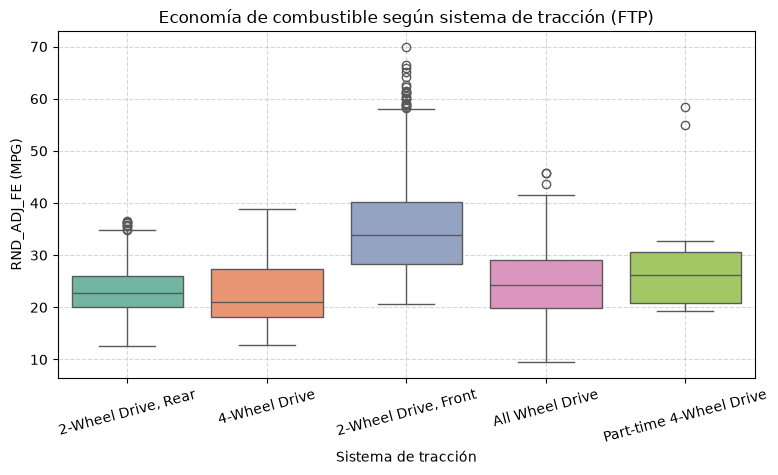

In [47]:
# Test de Kruskal-Wallis
stat_kw, p_kw = stats.kruskal(*grupos_traccion)
print(f"Test de Kruskal-Wallis: estadístico H={stat_kw:.3f}, p-valor={p_kw:.4e}")

# Boxplot comparativo
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df_traccion[df_traccion['Drive System Description'].isin(nombres_traccion)], 
            x='Drive System Description', y='RND_ADJ_FE', palette='Set2')
plt.title('Economía de combustible según sistema de tracción (FTP)')
plt.xlabel('Sistema de tracción')
plt.ylabel('RND_ADJ_FE (MPG)')
plt.xticks(rotation=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

el test de kruskal-wallis da un p-valor menor a 0.05, por lo tanto se rechaza la hipótesis nula y se concluye que existen diferencias significativas según el sistema de tracción. En el gráfico se puede ver que la tracción delantera (Front) es la más eficiente con una mediana de 33.8 MPG, mientras que los vehículos con tracción integral AWD (24.2 MPG), tracción trasera (22.8 MPG) y 4x4 (21.1 MPG) tienen rendimientos menores por el mayor peso del sistema y la resistencia mecánica. Se confirma la hipótesis.


# 3.6 - hipotesis C) Entre vehículos a combustion, las características técnicas del vehículo(peso, potencia, cilindrada, número de cilindros, transmisión y sistema de tracción) se encuentran asociadas conjuntamente con su eficiencia de combustible urbana..

para que ver que variables afecta la economia del combustible utilizamos regresion lineal

primero vamos a filtrar el dataset con lo relevante

In [48]:

#nos quedamos con los de combustion y manejo urbano
combustibles_excluir = ['Electricity', 'Hydrogen 5']
combustion = dataset[(~dataset['Test Fuel Type Description'].isin(combustibles_excluir)) & (dataset["Test Category"] == "FTP")]

analisamos las variables relevantes sus outliers

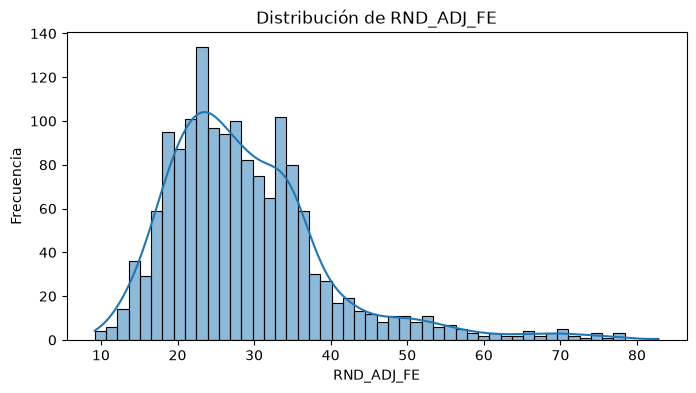

In [49]:
#historigrama para RND_ADJ_FE

plt.figure(figsize=(8, 4))
sns.histplot(
    combustion["RND_ADJ_FE"].dropna(),
    bins=50,
    kde=True,
    edgecolor="black"
)

plt.title("Distribución de RND_ADJ_FE")
plt.xlabel("RND_ADJ_FE")
plt.ylabel("Frecuencia")

plt.show()


no presenta outlier
vamos con el otro

In [50]:

combustion["Equivalent Test Weight (lbs.)"].describe()

count    1541.000000
mean     4592.553537
std       854.942725
min      2750.000000
25%      4000.000000
50%      4500.000000
75%      5250.000000
max      7000.000000
Name: Equivalent Test Weight (lbs.), dtype: float64

tampoco se observa outlier

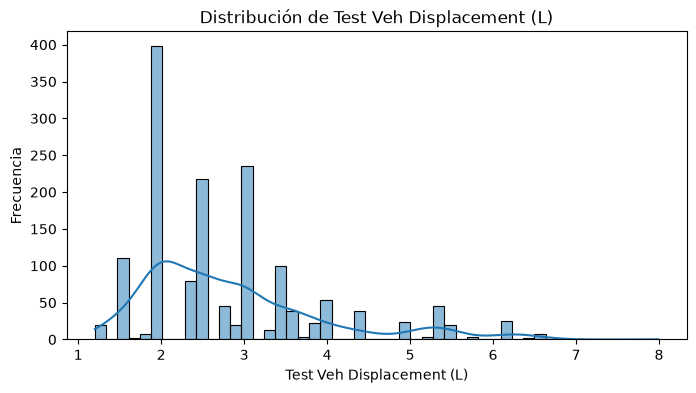

count    1541.000000
mean        2.846879
std         1.102689
min         1.200000
25%         2.000000
50%         2.500000
75%         3.445000
max         7.993000
Name: Test Veh Displacement (L), dtype: float64

In [51]:
plt.figure(figsize=(8, 4))
sns.histplot(
    combustion["Test Veh Displacement (L)"].dropna(),
    bins=50,
    kde=True,
    edgecolor="black"
)

plt.title("Distribución de Test Veh Displacement (L)")
plt.xlabel("Test Veh Displacement (L)")
plt.ylabel("Frecuencia")

plt.show()

combustion["Test Veh Displacement (L)"].describe()

tampoco presenta valor un valor exagerado o ireal dado el contexto

In [52]:
combustion["Rated Horsepower"].describe()

count    1541.000000
mean      312.521739
std       144.092364
min         1.000000
25%       195.000000
50%       286.000000
75%       375.000000
max      1500.000000
Name: Rated Horsepower, dtype: float64

hay un outlier sacamos las filas >= 1500

In [53]:
combustion["# of Cylinders and Rotors"].describe()

count    1538.000000
mean        5.182705
std         1.612746
min         3.000000
25%         4.000000
50%         4.000000
75%         6.000000
max        16.000000
Name: # of Cylinders and Rotors, dtype: float64

sacamos el outlier 16

In [54]:
#filtramos outlier relevantes
combustion = combustion[(combustion['Rated Horsepower'] < 1500)
                        & (combustion['# of Cylinders and Rotors'] < 16)]

# Selección de columnas clave y eliminación de nulos
cols_modelo = [
    'RND_ADJ_FE',                      # Y: Eficiencia Urbana (MPG)
    'Equivalent Test Weight (lbs.)',   # X1: Peso
    'Rated Horsepower',                # X2: Potencia
    'Test Veh Displacement (L)',       # X3: Cilindrada
    '# of Cylinders and Rotors',       # X4: Número de cilindros
    'Tested Transmission Type',        # X5: Transmisión (Categórica)
    'Drive System Description'         # X6: Tracción (Categórica)
]

df_model_data = combustion[cols_modelo].dropna().reset_index(drop=True)

df_reg = pd.get_dummies(df_model_data, columns=['Tested Transmission Type', 'Drive System Description'], drop_first=True, dtype=float)


ahora estandarizamos los datos

In [55]:
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

#Separamos la variable objetivo de las predictoras
x = df_reg.drop(columns=['RND_ADJ_FE'])
y = df_reg['RND_ADJ_FE']

#Estandarizamos las variables
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

#Metemos x_scaled en un dataframe para no perder el nombre de las columnas
x_scaled_df = pd.DataFrame(x_scaled,columns = x.columns)

#Vemos si se escalo correctamente
print('Antes de escalar:')
print(pd.DataFrame(x).describe().loc[['mean','std']])

print('Despues de escalar:')
print(pd.DataFrame(x_scaled_df).describe().loc[['mean','std']])

Antes de escalar:
      Equivalent Test Weight (lbs.)  Rated Horsepower  \
mean                    4593.770332        311.949902   
std                      855.507767        140.981010   

      Test Veh Displacement (L)  # of Cylinders and Rotors  \
mean                   2.844533                   5.175667   
std                    1.096001                   1.589469   

      Tested Transmission Type_Automated Manual- Selectable (e.g. Automated Manual with paddles)  \
mean                                           0.132726                                            
std                                            0.339389                                            

      Tested Transmission Type_Automatic  \
mean                            0.284320   
std                             0.451237   

      Tested Transmission Type_Continuously Variable  \
mean                                        0.130774   
std                                         0.337263   

      Tested Transmi

ajustamos el modelo

In [56]:
#Agregamos una constante como ordenada al origen
x_scaled_df = sm.add_constant(x_scaled_df)

#Ajustamos el modelo
model = sm.OLS(y, x_scaled_df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.692
Model:                            OLS   Adj. R-squared:                  0.689
Method:                 Least Squares   F-statistic:                     244.2
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        11:45:19   Log-Likelihood:                -4913.4
No. Observations:                1537   AIC:                             9857.
Df Residuals:                    1522   BIC:                             9937.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                                                                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

se puede observar que el f-static por su p-valor <0.05 que el modelo es signifitivo pero por el p-valor de omnibus y jarque-bera <0.05 no cumple el supuesto de normalidad de los datos

igual nos fijamos con qqplots

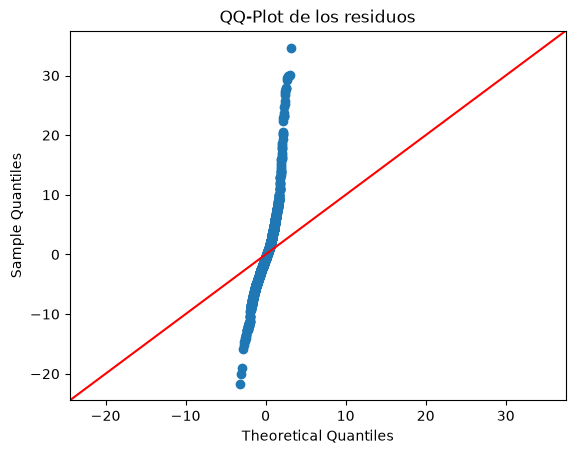

In [57]:
# QQ-Plot
sm.qqplot(model.resid, line='45')
plt.title("QQ-Plot de los residuos")
plt.show()

se puede ver claramento que no sigue el patron de normalidad terminar probando con shapiro

In [58]:
# aplicamos Shapiro-Wilk sobre los residuos
_, p = shapiro(model.resid)
print("p = %.4f" % (p))
# comparamos con el alpha
alpha = 0.05
if p > alpha:
    print("Se distribuyen normal (falló en rechazarse la hipótesis nula)")
else:
    print('No se distribuyen normal (se rechazó la hipótesis nula)')

p = 0.0000
No se distribuyen normal (se rechazó la hipótesis nula)


por lo tanto no es relevante este modelo por que falla uno de sus supuestos,Finalmente, concluimos que no se puede predecir la economia del combustible con
regresión lineal a través de las variables proporcionadas. Probablemente se podría estudiar
esta variable con un análisis no lineal pero, en base a la técnica utilizada, rechazamos la
hipótesis

# pca

Usaremos PCA para llevar el dataset reducido a un espacio de dos dimensiones y seguir analizando la relacion de caracteristicas tecnicas del vehiculo, devido a que regresion lineal no se puede usar por falta de su supuesto normal.

In [59]:
dataset_reducido= df_reg.drop('RND_ADJ_FE', axis=1)

#Estandarizamos los datos del dataset_reducido para que tengan la misma varianza
scaler = StandardScaler()
reducido_escalado = scaler.fit_transform(dataset_reducido)

#creamos una instancia de la clase PCA, indicando la cantidad de dimensiones deseadas
pca = PCA(n_components=2)
#Ajustamos el objeto pca usando los datos y transformamos los datos a la dimension requerida.
componentesPrincipales = pca.fit_transform(reducido_escalado)
#Chequeamos que se haya reducido correctamente la dimension impriendo la cantidad de filas y columnas de ambos datasets
print('Antes de PCA: {}'.format(dataset_reducido.shape))
print('Despues de PCA:{}'.format(componentesPrincipales.shape))


Antes de PCA: (1537, 14)
Despues de PCA:(1537, 2)


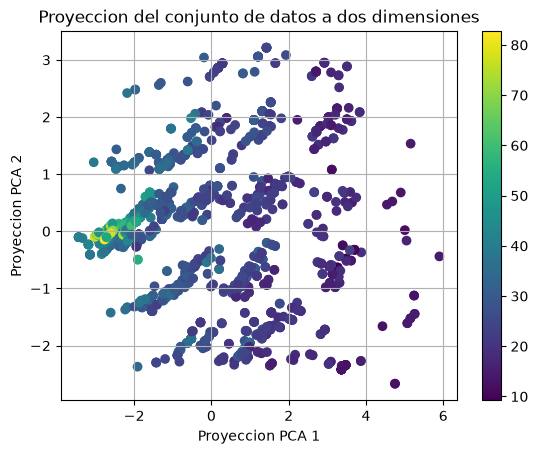

In [60]:
#Graficamos los datos del nuevo dataset reducido, indicando para los ejes x e y los primeros dos componentes principales
#Utilizamos el color para pintar los registros la economia del combustible asociado.
plt.scatter(componentesPrincipales[:,0], componentesPrincipales[:,1], c=df_reg['RND_ADJ_FE'], cmap='viridis')
#Agregamos una grilla, los nombres de los ejes, el titulo y una barra de color
plt.grid(True)
plt.xlabel('Proyeccion PCA 1')
plt.ylabel('Proyeccion PCA 2')
plt.title('Proyeccion del conjunto de datos a dos dimensiones')
plt.colorbar()
#Ajustamos el rango
plt.show()

la grafica muestra que los autos con ciertas carecteristicas tiene mayor economia de combustible (colores mas claros) en comparacion con los de la derecha (color mas oscuro), el modelo capta un 40% aprox de la varianza total de los datos 

In [61]:
pca.explained_variance_ratio_

array([0.26307722, 0.12189954])

Esto pareciera indicar que necesitaremos mas dimensiones para poder tener el 95% de la varianza y no perder informacion al reducir la dimensionalidad. 

#### T-Sne
Como la reducción con PCA nos explica poca varianza en solo dos dimensiones, haremos el mismo análisis con T-SNE, en donde las muestras proyectadas conservan la distancia, que facilita la visualización del gráfico.

Antes T-SNE: (1537, 14)
Despues T-SNE: (1537, 2)


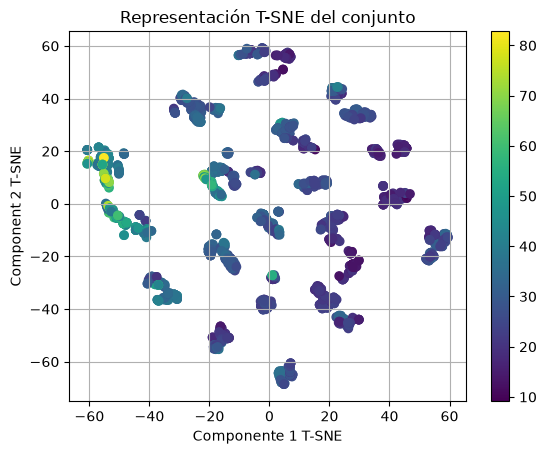

In [62]:
# importamos T-SNE
from sklearn.manifold import TSNE

# Creamos una instancia de la clase, lo ajustamos a nuestros datos, lo transformamos e indicamos random_state para que el grafic sea siempre igual
tsne = TSNE(n_components=2, random_state=10).fit_transform(reducido_escalado)
#Chequeamos que se haya reducido correctamente la dimension impriendo la cantidad de filas y columnas de ambos datasets
print('Antes T-SNE: {}'.format(reducido_escalado.shape))
print('Despues T-SNE: {}'.format(tsne.shape))

# graficamos los datos, el color de cada punto representa la economia del combustible asociado
plt.scatter(tsne[:,0], tsne[:,1], c=df_reg["RND_ADJ_FE"], cmap='viridis')
plt.grid(True)
plt.xlabel('Componente 1 T-SNE')
plt.ylabel('Component 2 T-SNE')
plt.title('Representación T-SNE del conjunto')
plt.colorbar()
plt.show()


En este caso, los datos están más agrupados debido a que t-SNE preserva la similitud local y captura relaciones no lineales de manera simultánea. Además, se puede observar un patrón claro de agrupamiento: las configuraciones de autos con mayor economía de combustible (colores más claros) se separan de aquellas con menor economía (colores más oscuros).

**En conclusión,la hipótesis queda totalmente validada,  los análisis multivariados confirman que el rendimiento de 
combustible es el resultado directo e inseparable del conjunto de estas decisiones de diseño técnico.**